# 06 · Mosaicism and MitoRead: what one blood genome can and cannot see

**Place in the argument.** A methodological extension. MVA type 1 produces *variegated*
aneuploidy: different cells gain or lose different chromosomes. This notebook asks what that
does to the standard allelic signal, shows how our own first explanation of the answer was
falsified, and then reports the one orthogonal readout the full alignment made possible, the
mitochondrial-to-nuclear depth ratio.

| Part | Evidence origin | Patient data? | What it can support |
|---|---|---|---|
| **A · BAF under variegation** | `SIMULATED` | **None** | A failure mode of a statistic, under stated assumptions |
| **A′ · the measured genome** | `MEASURED` + `DERIVED` | Aggregated | A chromosome-level description; not a karyotype, not a mosaic fraction |
| **B · MitoRead** | `MEASURED` + `DERIVED` | Aggregated | A composition-unadjusted ratio; not evidence of mitochondrial dysfunction |

The parts are kept apart on purpose. Presenting a simulated power curve or a coverage ratio as
if it were a functional measurement of this child is exactly the error the brief forbids.

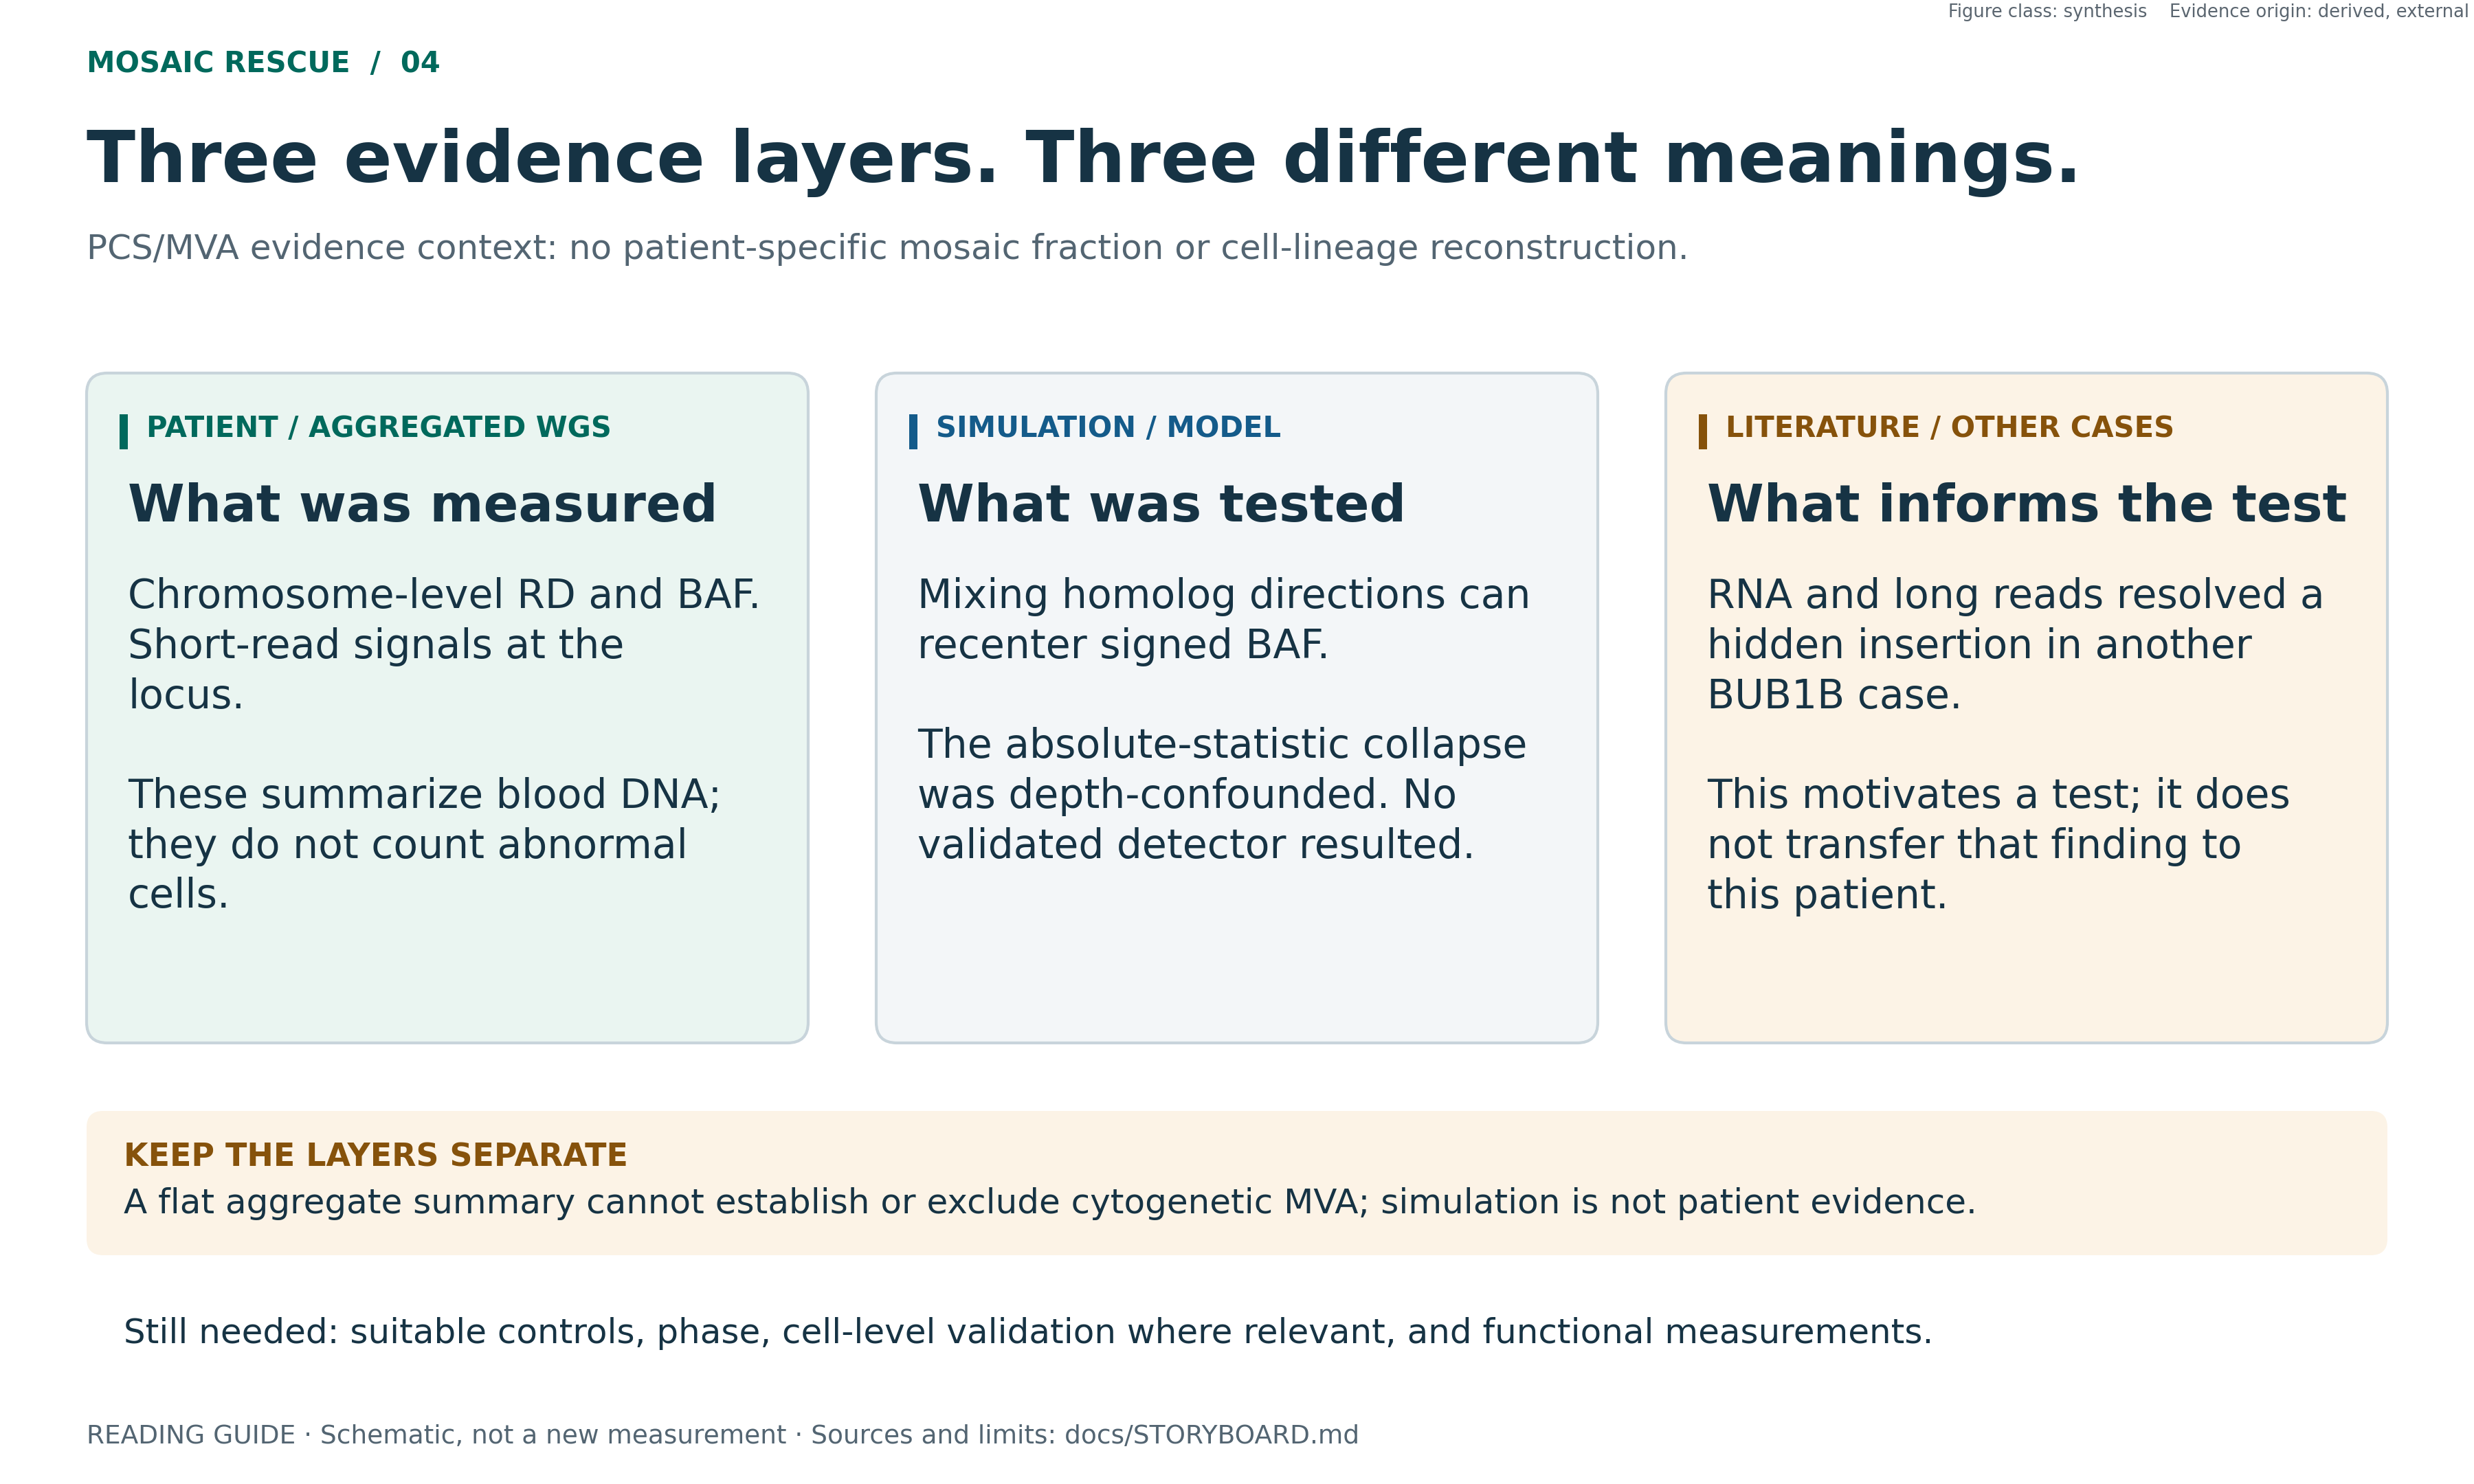

**`SYNTHESIS` · DERIVED / EXTERNAL.** The case WGS, the simulation and the literature answer different questions and are never merged. Reviewed figure, embedded without re-running the original analysis · [sources and limits](../docs/STORYBOARD.md) · [figure QA](../PUBLICATION_FIGURE_QA.md)

In [1]:
import sys, os, io, json, pickle, collections
os.chdir("..")                       # the pipeline uses paths relative to the repo root
sys.path.insert(0, ".")
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
from src.nb import figlib as fl      # inline figures + provenance captions
print("environment ready · figures in this notebook render inline, each with a provenance caption")

environment ready · figures in this notebook render inline, each with a provenance caption


In [2]:
fl.labels("What the figure shows", "What it cannot tell us about this child")
from IPython.display import Markdown, display

---

## Part A · Does the allelic signal survive variegation?

**The biological question.** Standard mosaicism callers assume *clonality*: one ancestral cell,
one gained homolog, so the B-allele fraction (BAF) at heterozygous sites moves away from 0.5.
In MVA each lineage can gain either homolog. **If half the gains are of one homolog and half of
the other, the shifts cancel in bulk sequencing.**

```
CLONAL       every cell gains the SAME homolog    BAF = 1/(2+f) ≈ 0.5 − f/4    shifted
VARIEGATED   each lineage gains one at random     BAF = 0.5 on average          cancels
             depth, in both cases                 (2+f)/2 × baseline            survives
```

**Preregistration.** `docs/DECISIONS.md` § EXP-015a was written *before* implementation, with
four predictions and a decision rule. Prediction #3 was the one that mattered: if a
coverage-dispersion index did not keep power where BAF cancels, the idea would be dropped.

In [3]:
sim = json.load(io.open("work/mosaic/dispersion_simulation.json", encoding="utf-8"))
R = {(r["mode"], round(r["fraction"], 2)): r for r in sim["results"]}
fr = sorted({round(r["fraction"], 2) for r in sim["results"]})

rows = ["| cell fraction | BAF · clonal | BAF · variegated | dispersion · clonal | dispersion · variegated |",
        "|---:|---:|---:|---:|---:|"]
for f in fr:
    c, v = R[("clonal", f)], R[("variegated", f)]
    rows.append(f"| {f*100:.0f} % | {c['power_baf']:.3f} | {v['power_baf']:.3f} | "
                f"{c['power_dispersion']:.3f} | {v['power_dispersion']:.3f} |")
display(Markdown(
    f"**Simulated detection power at a fixed false-positive rate of {sim['alpha']}.** "
    f"Seed {sim['seed']} (preregistered) · {sim['n_rep']} replicates per cell · "
    f"depth {sim['depth']}× · no patient data.\n\n" + "\n".join(rows)))

**Simulated detection power at a fixed false-positive rate of 0.05.** Seed 42 (preregistered) · 200 replicates per cell · depth 44× · no patient data.

| cell fraction | BAF · clonal | BAF · variegated | dispersion · clonal | dispersion · variegated |
|---:|---:|---:|---:|---:|
| 1 % | 0.045 | 0.055 | 0.060 | 0.060 |
| 2 % | 0.035 | 0.030 | 0.100 | 0.095 |
| 5 % | 0.070 | 0.030 | 0.380 | 0.300 |
| 10 % | 0.280 | 0.015 | 0.975 | 0.960 |
| 20 % | 1.000 | 0.000 | 1.000 | 1.000 |

### Main figure A · look at the distributions, not the summary

A mean cannot show cancellation: the summary statistic of a variegated genome looks like that
of a euploid one, and that is exactly the trap. The site-by-site BAF distribution, on the same
scale in all three scenarios, is what has to be inspected.

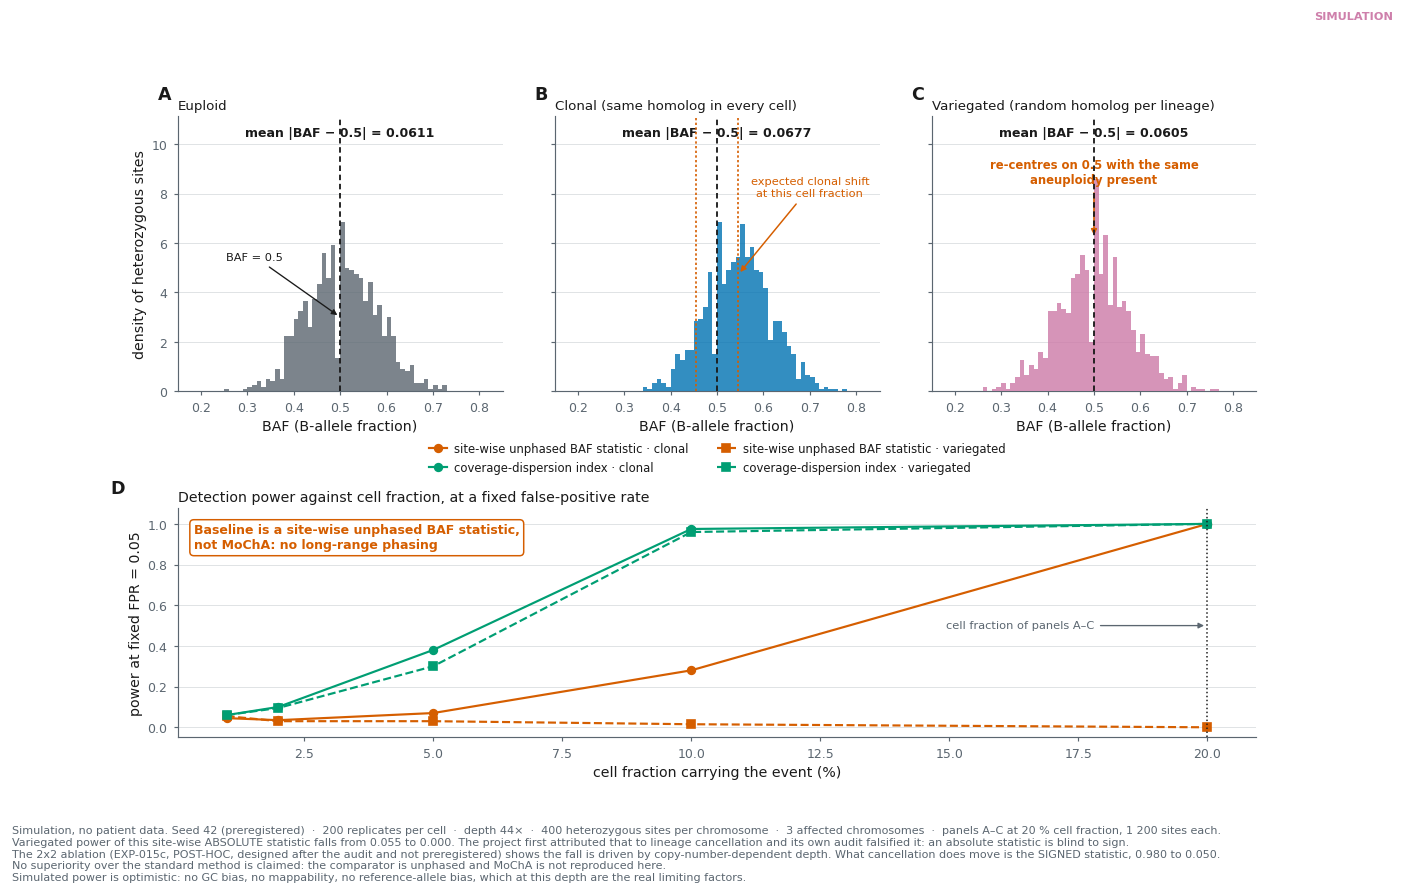

> **Main figure A · simulated BAF distributions and detection power**  
> `EXP-015a` · figure class `SIMULATION`, scientific figure · evidence origin `SIMULATED`  
> *What the figure shows.* on identical scales, the euploid genome centres on 0.5, the clonal genome shifts towards the two expected modes, and the variegated genome, with the same fraction of aneuploid cells, re-centres on 0.5. Panel D tracks the ABSOLUTE statistic, whose variegated power falls from 0.055 to 0.000. That fall is **not** caused by cancellation: the post-hoc ablation below shows it is driven by copy-number-dependent depth. Cancellation does move the SIGNED statistic, from 0.980 to 0.050.  
> **What it cannot tell us about this child.** nothing about this child: there is not one patient value in it. Nor does it show superiority over the standard method: the comparator is a site-wise unphased BAF statistic, not MoChA, and the panel says so. Simulated power is optimistic (no GC, mappability or reference-allele bias).  
> data: `src/mosaic/simulate_dispersion.py · seed 42` · library: `matplotlib` · provenance: `figures/pub/fig06_baf_cancellation.svg + .png 300 dpi`

In [4]:
from src.mosaic.simulate_dispersion import site_bafs
from src.figures import fig06_baf as FBAF

F = 0.20                                   # the fraction at which cancellation is complete
BAFS = {lab: site_bafs(sim["seed"] + i, 0.0 if mode == "null" else F, mode)
        for i, (lab, mode, _col) in enumerate(FBAF.SCEN)}
fig = FBAF.build(sim, BAFS, F)
_pv = [r["power_baf"] for r in sim["results"] if r["mode"] == "variegated"]
fl.pub(fig, "Main figure A · simulated BAF distributions and detection power",
       "EXP-015a", "SIMULATED", "SIMULATION",
       f"on identical scales, the euploid genome centres on 0.5, the clonal genome shifts "
       f"towards the two expected modes, and the variegated genome, with the same fraction of "
       f"aneuploid cells, re-centres on 0.5. Panel D tracks the ABSOLUTE statistic, whose "
       f"variegated power falls from {_pv[0]:.3f} to {_pv[-1]:.3f}. That fall is **not** caused "
       f"by cancellation: the post-hoc ablation below shows it is driven by copy-number-dependent "
       f"depth. Cancellation does move the SIGNED statistic, from 0.980 to 0.050.",
       "nothing about this child: there is not one patient value in it. Nor does it show "
       "superiority over the standard method: the comparator is a site-wise unphased BAF "
       "statistic, not MoChA, and the panel says so. Simulated power is optimistic (no GC, "
       "mappability or reference-allele bias).",
       source=f"src/mosaic/simulate_dispersion.py · seed {sim['seed']}",
       lib="matplotlib", slug="fig06_baf_cancellation")

### The four preregistered predictions, scored against the simulation

The verdicts are those recorded in the preregistration. The values are read from the simulation
output above, not typed in. Two predictions held and two failed; the failures are kept because
they change what can be claimed.

In [5]:
def P(mode, f, stat):
    return R[(mode, f)]["power_" + stat]

pred = [
 ("#1", "BAF detects clonal events from low cell fractions",
  f"clonal BAF power {P('clonal', 0.05, 'baf'):.2f} at 5 %, {P('clonal', 0.1, 'baf'):.2f} at 10 %",
  "**failed**"),
 ("#2", "BAF collapses under variegation",
  f"variegated BAF power {P('variegated', 0.2, 'baf'):.3f} at 20 % (absolute statistic)",
  "held, **for the wrong reason**: see the ablation below"),
 ("#3", "Dispersion keeps power under variegation",
  f"variegated dispersion power {P('variegated', 0.1, 'dispersion'):.2f} at 10 %",
  "held"),
 ("#4", "Dispersion does not beat BAF in clonal events",
  f"clonal, 10 %: dispersion {P('clonal', 0.1, 'dispersion'):.2f} vs BAF {P('clonal', 0.1, 'baf'):.2f}",
  "**failed**: the BAF baseline is weak, not our index strong"),
]
md = ["| | Prediction | Simulated value | Verdict |", "|---|---|---|---|"]
md += [f"| {k} | {text} | {val} | {verdict} |" for k, text, val, verdict in pred]
display(Markdown("\n".join(md)))

| | Prediction | Simulated value | Verdict |
|---|---|---|---|
| #1 | BAF detects clonal events from low cell fractions | clonal BAF power 0.07 at 5 %, 0.28 at 10 % | **failed** |
| #2 | BAF collapses under variegation | variegated BAF power 0.000 at 20 % (absolute statistic) | held, **for the wrong reason**: see the ablation below |
| #3 | Dispersion keeps power under variegation | variegated dispersion power 0.96 at 10 % | held |
| #4 | Dispersion does not beat BAF in clonal events | clonal, 10 %: dispersion 0.97 vs BAF 0.28 | **failed**: the BAF baseline is weak, not our index strong |

### The test that falsified our first explanation

Prediction #2 was first scored as confirmed by reading it on the **absolute** statistic
`|BAF − 0.5|`. An absolute value is blind to sign, so it cannot be the statistic that
cancellation acts on. A 2 × 2 ablation (EXP-015c) crossed homolog direction (fixed vs mixed)
with the depth model (copy-number-scaled vs matched to the null). It was designed **after** the
audit and is labelled **POST-HOC**. The preregistration is not rewritten; the correction sits
next to it.

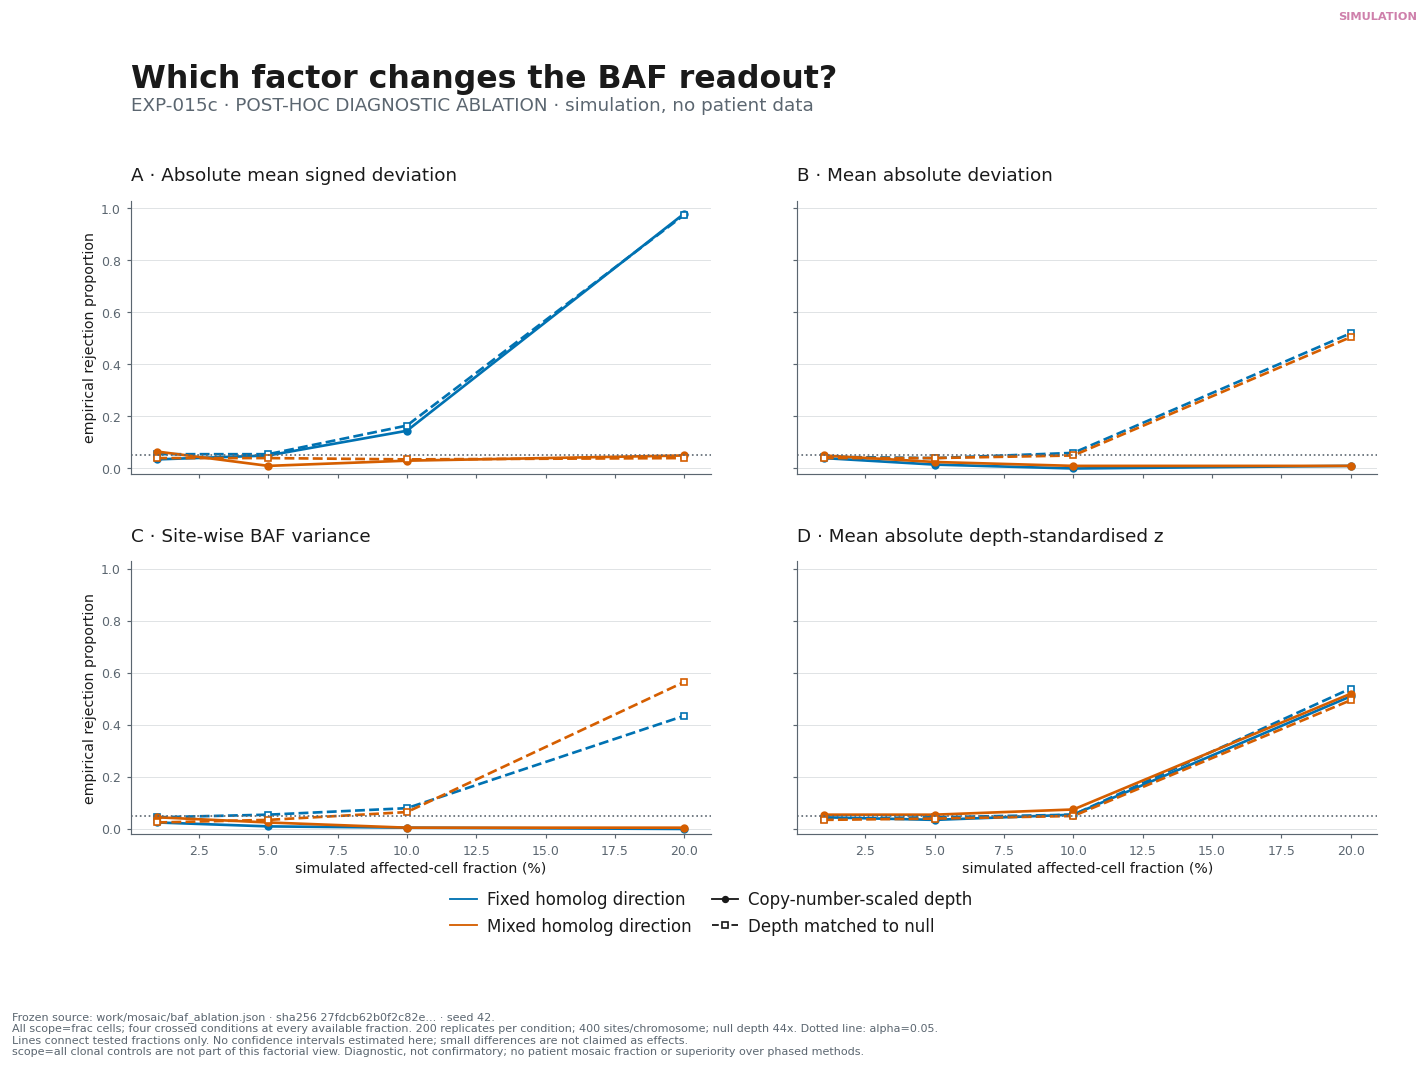

> **Figure A2 · factorial ablation: which factor moves each statistic**  
> `EXP-015c · POST-HOC` · figure class `SIMULATION`, scientific figure · evidence origin `SIMULATED`  
> *What the figure shows.* homolog direction (blue vs vermilion) separates the curves only for the SIGNED statistic (panel A): mixed direction flattens it, which is cancellation. For the absolute deviation and the variance (panels B and C) the split is instead between copy-number-scaled depth (solid, flat) and depth matched to the null (dashed, rising): the loss first attributed to cancellation is a depth effect. Standardising by depth (panel D) makes all four conditions converge.  
> **What it cannot tell us about this child.** anything about the patient, and it is diagnostic, not confirmatory: it was designed after the audit. No confidence intervals are drawn, so small differences between curves are not claimed as effects.  
> data: `work/mosaic/baf_ablation.json · sha256 27fdcb62b0f2c82e… · seed 42` · library: `matplotlib` · provenance: `figures/pub/fig12_baf_factorial_ablation.svg + .png 300 dpi`

In [6]:
from src.figures import fig12_ablation as FABL

fig, abl = FABL.load_and_build()          # refuses to draw if the frozen source hash changed
fl.pub(fig, "Figure A2 · factorial ablation: which factor moves each statistic",
       "EXP-015c · POST-HOC", "SIMULATED", "SIMULATION",
       "homolog direction (blue vs vermilion) separates the curves only for the SIGNED "
       "statistic (panel A): mixed direction flattens it, which is cancellation. For the "
       "absolute deviation and the variance (panels B and C) the split is instead between "
       "copy-number-scaled depth (solid, flat) and depth matched to the null (dashed, rising): "
       "the loss first attributed to cancellation is a depth effect. Standardising by depth "
       "(panel D) makes all four conditions converge.",
       "anything about the patient, and it is diagnostic, not confirmatory: it was designed "
       "after the audit. No confidence intervals are drawn, so small differences between "
       "curves are not claimed as effects.",
       source=f"work/mosaic/baf_ablation.json · sha256 {FABL.SHA256[:16]}… · seed {abl['seed']}",
       lib="matplotlib", slug="fig12_baf_factorial_ablation")

### Decision for Part A

| Hypothesis | Status |
|---|---|
| **EXP-015a** · the cancellation mechanism | **Survives** for the signed statistic; the failure mode is reproduced and quantified |
| **EXP-015a** · "cancellation explains the loss of absolute power" | **Falsified** by EXP-015c; the cause is depth |
| **EXP-015b** · the dispersion index as a detector | **Parked, not validated**: the comparator is not MoChA |

What rose in status is the **mechanism**, not relative performance: we do not claim to be "more
powerful than MoChA". Applying the index to the patient stays **blocked**: it needs control
genomes processed with an identical pipeline, and none exist.

## Part A′ · What the measured genome actually shows

The simulation says what *could* hide. The patient's aggregated read depth (RD) and BAF, from
the GO 2B CNVpytor run on the full alignment, say what *is visible*. The figure is read from
frozen artifacts and refuses to draw if their hashes change.

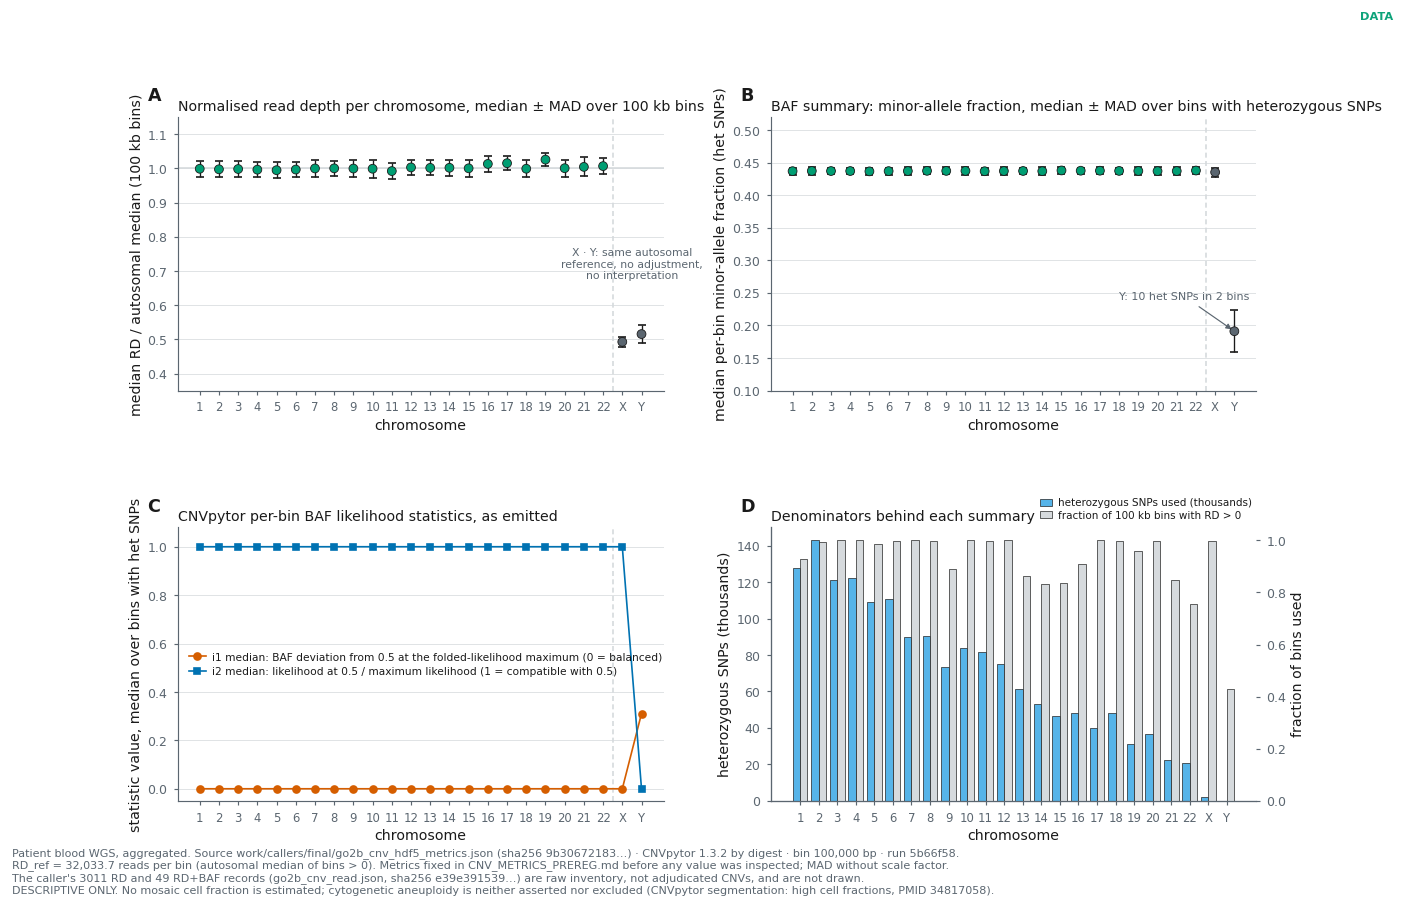

> **Figure A′ · measured read depth and BAF per chromosome (GO 2B, frozen)**  
> `GO 2B · CNVpytor` · figure class `DATA`, scientific figure · evidence origin `MEASURED + DERIVED`  
> *What the figure shows.* chromosome-level read-depth and allelic-balance summaries of the full alignment, with their denominators. CNVpytor did not emit an RD+BAF CNV overlapping the BUB1B gene body.  
> **What it cannot tell us about this child.** a karyotype, a count of cells or clones, or a mosaic cell fraction. After Part A, a variegated low-level aneuploidy could leave BAF near 0.5, so a quiet BAF here is not evidence of absence.  
> data: `work/callers/final/ (hash-checked against MANIFEST.json)` · library: `matplotlib` · provenance: `figures/pub/fig09_cnvpytor_chromosome_rd_baf.svg + .png 300 dpi`

In [7]:
from src.figures import fig09_cnv_chromosomes as FCNV

fig, _cnv = FCNV.load_and_build()
fl.pub(fig, "Figure A′ · measured read depth and BAF per chromosome (GO 2B, frozen)",
       "GO 2B · CNVpytor", "MEASURED + DERIVED", "DATA",
       "chromosome-level read-depth and allelic-balance summaries of the full alignment, "
       "with their denominators. CNVpytor did not emit an RD+BAF CNV overlapping the BUB1B "
       "gene body.",
       "a karyotype, a count of cells or clones, or a mosaic cell fraction. After Part A, a "
       "variegated low-level aneuploidy could leave BAF near 0.5, so a quiet BAF here is not "
       "evidence of absence.",
       source="work/callers/final/ (hash-checked against MANIFEST.json)",
       lib="matplotlib", slug="fig09_cnvpytor_chromosome_rd_baf")

---

## Part B · MitoRead: a mitochondrial-to-nuclear depth ratio

**Why this branch exists.** Aneuploidy imposes proteotoxic and mitochondrial stress on cells
(one of the Track 2 evidence bridges), so mitochondrial DNA content in blood is an orthogonal
readout the genome already contains. It needs no variants: it is a ratio of coverages.

**How it evolved.** The first version (EXP-014a) was a technical pilot on a single lane:
k-mer matching of a subsample of L001 reads against the mitochondrial reference. It showed the
signal was extractable and nothing more, because nuclear mitochondrial segments (NUMTs) could
not be addressed without an alignment. Once GO 2B rebuilt the full alignment, MitoRead was run
on it. **The aligned readout below replaces the pilot as the project's MitoRead result.** The
two numbers are not placed on one axis because their denominators are defined differently.

In [8]:
import hashlib

# The GO 2B operational table sealed the hash of every MitoRead output. Fail closed.
_op = json.load(io.open("work/callers/stop_2026-09-09/tabla_operacional_go2b.json", encoding="utf-8"))

def _sealed(rel, x=_op):
    if isinstance(x, dict):
        v = x.get(rel)
        if isinstance(v, dict) and "sha256" in v:
            return v["sha256"]
        x = list(x.values())
    if isinstance(x, list):
        for v in x:
            r = _sealed(rel, v)
            if r:
                return r
    return None

for rel in ("mito/mitoread.json", "mito/chrM_q0.txt", "mito/chrM_q30.txt"):
    got = hashlib.sha256(open("work/callers/" + rel, "rb").read()).hexdigest()
    exp = _sealed(rel)
    if got != exp:
        raise RuntimeError(f"{rel}: sha256 {got[:12]} differs from the sealed {str(exp)[:12]}; not drawing")

mr = json.load(io.open("work/callers/mito/mitoread.json", encoding="utf-8"))
dq0 = np.loadtxt("work/callers/mito/chrM_q0.txt", usecols=2)
dq30 = np.loadtxt("work/callers/mito/chrM_q30.txt", usecols=2)
auto = {int(k): v for k, v in mr["per_autosome_mean_depth"].items()}
sens = mr["sensitivity_to_denominator"]

display(Markdown(
    "| Readout on the full alignment (GO 2B) | Value |\n|---|---:|\n"
    f"| chrM median depth, MAPQ ≥ 30 | {mr['chrM_median_depth_MAPQ30']:,}× |\n"
    f"| chrM median depth, MAPQ 0 | {mr['chrM_median_depth_MAPQ0']:,}× |\n"
    f"| chrM depth retained at MAPQ ≥ 30 | {mr['mapq30_retained_fraction']:.3f} |\n"
    f"| autosomal weighted mean depth | {mr['autosomal_weighted_mean_depth']}× |\n"
    f"| **mtDNA : nuclear ratio, MAPQ ≥ 30** | **{mr['ratio_mtDNA_to_nuclear_MAPQ30']}** |\n"
    f"| same ratio if a single autosome is the denominator | {sens['max_autosome']} to {sens['min_autosome']} |\n\n"
    "All three source files match the hashes sealed in the GO 2B operational table."))

| Readout on the full alignment (GO 2B) | Value |
|---|---:|
| chrM median depth, MAPQ ≥ 30 | 4,223× |
| chrM median depth, MAPQ 0 | 4,306× |
| chrM depth retained at MAPQ ≥ 30 | 0.981 |
| autosomal weighted mean depth | 41.84× |
| **mtDNA : nuclear ratio, MAPQ ≥ 30** | **100.9** |
| same ratio if a single autosome is the denominator | 95.8 to 128.9 |

All three source files match the hashes sealed in the GO 2B operational table.

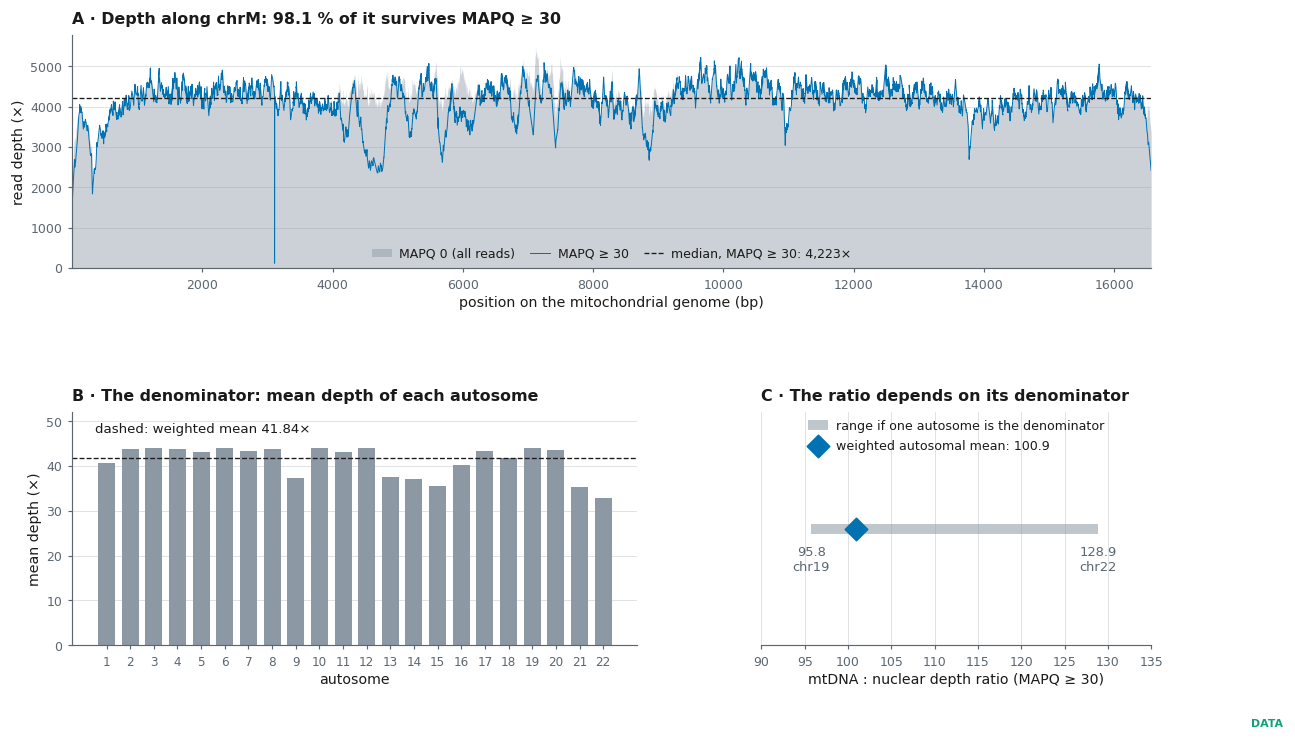

> **Figure B · MitoRead on the full alignment**  
> `GO 2B · MitoRead` · figure class `DATA`, scientific figure · evidence origin `MEASURED + DERIVED`  
> *What the figure shows.* mitochondrial depth is about 101 times the autosomal depth, and almost all of it survives the MAPQ ≥ 30 filter. Panel C shows how much the number depends on which nuclear depth is taken as the denominator: that spread is the honest resolution of the value.  
> **What it cannot tell us about this child.** mitochondrial dysfunction, or a copy number per cell. The ratio is not adjusted for cell composition (no blood or platelet count), and converting it into copies per cell would assume a nuclear ploidy of 2, which is exactly what cannot be assumed in variegated mosaic aneuploidy. MAPQ ≥ 30 measures mapping confidence, not origin: NUMT-derived reads are neither quantified nor excluded. No control genomes went through the same pipeline, so the value is descriptive, not comparable. Lower mean depths on some autosomes in panel B are not interpreted here; Figure A′ is the copy-number readout.  
> data: `mitoread.json + per-base chrM depth at MAPQ 0 and 30` · library: `matplotlib` · provenance: `work/callers/mito/ · hashes sealed in tabla_operacional_go2b.json`

In [9]:
fig = plt.figure(figsize=(11.6, 6.6))
gs = fig.add_gridspec(2, 2, height_ratios=[1.0, 1.0], width_ratios=[1.45, 1.0],
                      hspace=0.62, wspace=0.26)
axA = fig.add_subplot(gs[0, :]); axB = fig.add_subplot(gs[1, 0]); axC = fig.add_subplot(gs[1, 1])

# A · depth along the mitochondrial genome, under both mapping-quality filters
pos = np.arange(1, len(dq30) + 1)
axA.fill_between(pos, dq0, color=fl.FLOW, alpha=0.45, lw=0, label="MAPQ 0 (all reads)", rasterized=True)
axA.plot(pos, dq30, color=fl.BLUE, lw=0.6, label="MAPQ ≥ 30", rasterized=True)
axA.axhline(mr["chrM_median_depth_MAPQ30"], color=fl.INK, ls="--", lw=0.8,
            label=f"median, MAPQ ≥ 30: {mr['chrM_median_depth_MAPQ30']:,}×")
axA.set_xlim(1, len(pos)); axA.set_ylim(0, max(dq0.max(), dq30.max()) * 1.05); axA.grid(axis="y")
axA.set_xlabel("position on the mitochondrial genome (bp)")
axA.set_ylabel("read depth (×)")
fl.title(axA, f"A · Depth along chrM: {mr['mapq30_retained_fraction']*100:.1f} % of it survives MAPQ ≥ 30")
axA.legend(loc="lower center", ncol=3)

# B · the denominator: mean depth of every autosome
ks = sorted(auto)
axB.bar([str(k) for k in ks], [auto[k] for k in ks], color=fl.FLOW, width=0.72)
axB.axhline(mr["autosomal_weighted_mean_depth"], color=fl.INK, ls="--", lw=0.8)
axB.text(-0.5, 47.5, f"dashed: weighted mean {mr['autosomal_weighted_mean_depth']}×",
         ha="left", fontsize=8)
axB.set_ylim(0, 52); axB.grid(axis="y")
axB.set_xlabel("autosome"); axB.set_ylabel("mean depth (×)")
fl.title(axB, "B · The denominator: mean depth of each autosome")
axB.tick_params(axis="x", labelsize=7.2)

# C · the same ratio under each single-autosome denominator: an interval, not a trend
med30 = mr["chrM_median_depth_MAPQ30"]
r_by = {k: med30 / auto[k] for k in ks}
lo, hi = min(r_by, key=r_by.get), max(r_by, key=r_by.get)
axC.hlines(0, r_by[lo], r_by[hi], color=fl.FLOW, lw=6, alpha=0.55, zorder=2,
           label="range if one autosome is the denominator")
axC.scatter([mr["ratio_mtDNA_to_nuclear_MAPQ30"]], [0], s=90, marker="D", color=fl.BLUE,
            zorder=4, label=f"weighted autosomal mean: {mr['ratio_mtDNA_to_nuclear_MAPQ30']}")
for k, va, dy in ((lo, "top", -10), (hi, "top", -10)):
    axC.annotate(f"{r_by[k]:.1f}\nchr{k}", (r_by[k], 0), xytext=(0, dy), textcoords="offset points",
                 ha="center", va=va, fontsize=7.8, color=fl.SOFT)
axC.set_yticks([]); axC.set_ylim(-1, 1); axC.set_xlim(90, 135); axC.grid(axis="x")
axC.spines["left"].set_visible(False)
axC.set_xlabel("mtDNA : nuclear depth ratio (MAPQ ≥ 30)")
fl.title(axC, "C · The ratio depends on its denominator")
axC.legend(loc="upper center", fontsize=7.6)

fl.done(fig, "Figure B · MitoRead on the full alignment", "GO 2B · MitoRead",
        "MEASURED + DERIVED", "DATA",
        f"mitochondrial depth is about {mr['ratio_mtDNA_to_nuclear_MAPQ30']:.0f} times the "
        "autosomal depth, and almost all of it survives the MAPQ ≥ 30 filter. Panel C shows how "
        "much the number depends on which nuclear depth is taken as the denominator: that spread "
        "is the honest resolution of the value.",
        "mitochondrial dysfunction, or a copy number per cell. The ratio is not adjusted for "
        "cell composition (no blood or platelet count), and converting it into copies per cell "
        "would assume a nuclear ploidy of 2, which is exactly what cannot be assumed in "
        "variegated mosaic aneuploidy. MAPQ ≥ 30 measures mapping confidence, not origin: "
        "NUMT-derived reads are neither quantified nor excluded. No control genomes went "
        "through the same pipeline, so the value is descriptive, not comparable. Lower mean "
        "depths on some autosomes in panel B are not interpreted here; Figure A′ is the "
        "copy-number readout.",
        prov="work/callers/mito/ · hashes sealed in tabla_operacional_go2b.json",
        source="mitoread.json + per-base chrM depth at MAPQ 0 and 30", lib="matplotlib")

In [10]:
mp = json.load(io.open("work/mito/pilot_l001.json", encoding="utf-8"))
display(Markdown(
    "**Superseded pilot, kept for the record (EXP-014a).** "
    f"{mp['reads']:,} L001 reads examined; {mp['mito_reads']:,} "
    f"({100*mp['fraction']:.3f} %) matched the mitochondrial reference by 31-bp k-mers; naive "
    f"estimate {mp['mtdna_cn_estimate']:.0f} copy-equivalents under the pilot's assumptions. "
    "Its job was to show the branch was technically executable. A single lane is not full "
    "depth and NUMTs could not be addressed, so it is not used as a result."))

**Superseded pilot, kept for the record (EXP-014a).** 2,000,000 L001 reads examined; 1,382 (0.069 %) matched the mitochondrial reference by 31-bp k-mers; naive estimate 259 copy-equivalents under the pilot's assumptions. Its job was to show the branch was technically executable. A single lane is not full depth and NUMTs could not be addressed, so it is not used as a result.

### Decision for Part B

| | Status |
|---|---|
| **EXP-014a** · L001 pilot | **Superseded** by the aligned readout; it established feasibility only |
| **MitoRead on the full alignment** (GO 2B) | **Interpretable within its ceiling**: a cell-composition-unadjusted, WGS-derived blood mtDNA:nuclear ratio |
| **EXP-014b** · biological interpretation | **Blocked**: needs a contemporaneous blood count and control genomes processed identically |

**The most attackable assumption of the branch** is that mitochondrial content in peripheral
blood reflects the mitochondrial state of muscle or kidney. With one bulk sample there is no
internal gradient: it is a single point, not a dose-response curve.

## What this notebook contributes

1. **A methodological result.** In variegated aneuploidy a bulk allelic statistic can lose its
   signal by sign cancellation, and an absolute statistic can lose it for a different reason,
   depth. We found the second by auditing our own first explanation.
2. **A measured description** of the child's genome at chromosome level, with no claim about
   cells, clones or fractions.
3. **An orthogonal readout** (MitoRead) with its ceiling written next to it.

**What would move this branch.** Control genomes processed with the identical pipeline; a
contemporaneous blood count; and, for mosaicism itself, a phased method such as MoChA or
single-cell data. None of these is a computation we can run on the data we have.